# Генетический алгоритм для плана дежурств на неделю

**Лабораторная работа № 2, вариант 10.** Решается дискретная задача составления расписания с ограничениями. Используются собственная реализация генетического алгоритма из `duty_ga.py`, бинарная матрица назначений, специализированные операторы, ремонт и штрафы. Готовые оптимизаторы не применяются.

Имеются 7 сотрудников, 7 дней и 3 смены в каждом дне. Каждую из 21 смены должен обслужить ровно один сотрудник. Смена $(d,s)$ кодируется индексом $t=3d+s$.

**Генотип:** бинарная матрица $x\in\{0,1\}^{7\times21}$, где $x_{it}=1$ означает назначение сотрудника $i$ на смену $t$. **Фенотип:** таблица дежурств; декодирование заключается в выборе единичного элемента каждого столбца.

## Входные данные

Данные синтетические и генерируются с фиксированным `seed=202610`. Для каждой пары «сотрудник — смена» стоимость предпочтения выбирается из 0, 1 и 4 с вероятностями 0.25, 0.55 и 0.20. Затем независимо 10% ячеек получают значение 9 — сотрудник недоступен. Значения 0, 1 и 4 означают желательную, нейтральную и нежелательную смену.

Полученный экземпляр содержит 21 событие-дежурство. Ограничения на одну смену в день и запрет перехода «ночь — следующее утро» задают 147 и 42 парных конфликта соответственно, что превышает требуемый минимум в 10 ограничений конфликтности. Генератор проверяет существование допустимого решения конструктивной эвристикой.

In [1]:
%matplotlib inline
import json
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from duty_ga import (
    DAYS, SHIFTS, GAConfig, GeneticAlgorithm, constructive_schedule,
    generate_problem, is_feasible, random_genome, repair,
    save_instance, schedule_table, solution_metrics,
)

for directory in (Path('configs'), Path('results'), Path('plots')):
    directory.mkdir(exist_ok=True)

problem = generate_problem()
save_instance(problem, Path('configs/problem_instance.json'))
columns = [f'{DAYS[t // 3][:2]}-{SHIFTS[t % 3]}' for t in range(problem.n_slots)]
preferences_df = pd.DataFrame(problem.preferences, index=problem.employees, columns=columns)
print('Матрица предпочтений (9 — сотрудник недоступен):')
display(preferences_df)
heuristic_x = constructive_schedule(problem, np.random.default_rng(problem.data_seed + 1))
print('Проверка экземпляра конструктивной эвристикой:', solution_metrics(problem, heuristic_x))

Матрица предпочтений (9 — сотрудник недоступен):


,По-Утро,По-День,По-Ночь,Вт-Утро,Вт-День,Вт-Ночь,Ср-Утро,Ср-День,Ср-Ночь,Че-Утро,...,Че-Ночь,Пя-Утро,Пя-День,Пя-Ночь,Су-Утро,Су-День,Су-Ночь,Во-Утро,Во-День,Во-Ночь
Сотрудник 1,0,0,1,9,0,1,1,1,1,1,...,1,0,9,4,1,4,0,9,0,1
Сотрудник 2,4,4,9,1,4,0,0,4,0,1,...,4,1,1,4,1,1,9,1,1,1
Сотрудник 3,1,1,0,1,9,1,4,1,1,1,...,1,1,1,4,1,4,1,4,9,1
Сотрудник 4,9,1,1,1,4,4,0,4,9,4,...,1,9,9,1,1,0,4,0,1,1
Сотрудник 5,0,4,1,4,1,4,1,1,9,1,...,1,1,1,0,0,4,0,1,1,1
Сотрудник 6,9,1,1,0,9,9,1,1,1,1,...,1,1,1,9,1,0,0,0,1,0
Сотрудник 7,1,4,1,0,1,1,1,4,0,0,...,1,1,1,1,1,4,1,0,4,4


Проверка экземпляра конструктивной эвристикой: {'coverage': 0, 'daily': 0, 'rest': 0, 'limit': 0, 'unavailable': 0, 'hard_violations': 0, 'preference': 11, 'imbalance': 0.0, 'objective': 11.0, 'loads': [3, 3, 3, 3, 3, 3, 3]}


## Ограничения и целевая функция

Пусть $L_i=\sum_t x_{it}$ — число дежурств сотрудника. Жёсткие ограничения:

1. покрытие: $\sum_i x_{it}=1$ для каждой смены;
2. не более одной смены сотрудника в день: $\sum_{s=0}^{2}x_{i,3d+s}\leq1$;
3. отдых: запрещена ночная смена перед утренней следующего дня;
4. недельный лимит: $L_i\leq4$;
5. запрет назначения при $p_{it}=9$.

Минимизируется мягкая цель

$$f(x)=\sum_{i,t}p_{it}x_{it}+2\sum_i(L_i-3)^2.$$

Первое слагаемое учитывает предпочтения, второе — отклонение нагрузки от средних трёх смен. При ремонте фитнес равен $f(x)$. При штрафном подходе $F(x)=f(x)+1000H(x)$, где $H(x)$ — суммарное число нарушений пяти групп. Коэффициент 1000 заведомо больше возможной мягкой цели допустимого решения, поэтому любое допустимое решение предпочтительнее нарушающего ограничения.

## Примеры допустимых и недопустимых решений

Первые два решения построены эвристикой и ремонтом случайного генотипа. Третье — случайное назначение без ремонта. В четвёртом намеренно удалено назначение первой смены и один сотрудник поставлен на все смены понедельника.

In [2]:
feasible_examples = [
    heuristic_x,
    repair(problem, random_genome(problem, np.random.default_rng(2027)), np.random.default_rng(2028)),
]
invalid_random = random_genome(problem, np.random.default_rng(2029))
invalid_modified = heuristic_x.copy()
invalid_modified[:, 0] = 0
invalid_modified[0, 0:3] = 1
infeasible_examples = [invalid_random, invalid_modified]

assert all(is_feasible(problem, x) for x in feasible_examples)
assert not np.array_equal(feasible_examples[0], feasible_examples[1])
assert all(not is_feasible(problem, x) for x in infeasible_examples)

example_payload = {}
for label, genome in zip(('Допустимое 1', 'Допустимое 2', 'Недопустимое 1', 'Недопустимое 2'), feasible_examples + infeasible_examples):
    metrics = solution_metrics(problem, genome)
    example_payload[label] = {'genome': genome.tolist(), 'metrics': metrics}
    print(f'\n{label}: {metrics}')
    display(schedule_table(problem, genome))
Path('results/solution_examples.json').write_text(json.dumps(example_payload, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')


Допустимое 1: {'coverage': 0, 'daily': 0, 'rest': 0, 'limit': 0, 'unavailable': 0, 'hard_violations': 0, 'preference': 11, 'imbalance': 0.0, 'objective': 11.0, 'loads': [3, 3, 3, 3, 3, 3, 3]}


,Утро,День,Ночь
Понедельник,Сотрудник 1,Сотрудник 4,Сотрудник 3
Вторник,Сотрудник 6,Сотрудник 7,Сотрудник 2
Среда,Сотрудник 5,Сотрудник 3,Сотрудник 7
Четверг,Сотрудник 6,Сотрудник 1,Сотрудник 5
Пятница,Сотрудник 2,Сотрудник 3,Сотрудник 4
Суббота,Сотрудник 5,Сотрудник 4,Сотрудник 6
Воскресенье,Сотрудник 7,Сотрудник 1,Сотрудник 2



Допустимое 2: {'coverage': 0, 'daily': 0, 'rest': 0, 'limit': 0, 'unavailable': 0, 'hard_violations': 0, 'preference': 10, 'imbalance': 0.0, 'objective': 10.0, 'loads': [3, 3, 3, 3, 3, 3, 3]}


,Утро,День,Ночь
Понедельник,Сотрудник 5,Сотрудник 1,Сотрудник 3
Вторник,Сотрудник 6,Сотрудник 7,Сотрудник 2
Среда,Сотрудник 4,Сотрудник 6,Сотрудник 7
Четверг,Сотрудник 5,Сотрудник 1,Сотрудник 4
Пятница,Сотрудник 2,Сотрудник 3,Сотрудник 5
Суббота,Сотрудник 6,Сотрудник 4,Сотрудник 1
Воскресенье,Сотрудник 7,Сотрудник 2,Сотрудник 3



Недопустимое 1: {'coverage': 0, 'daily': 3, 'rest': 1, 'limit': 2, 'unavailable': 3, 'hard_violations': 9, 'preference': 60, 'imbalance': 48.0, 'objective': 108.0, 'loads': [4, 6, 3, 4, 1, 3, 0]}


,Утро,День,Ночь
Понедельник,Сотрудник 2,Сотрудник 6,Сотрудник 2
Вторник,Сотрудник 1,Сотрудник 1,Сотрудник 3
Среда,Сотрудник 1,Сотрудник 6,Сотрудник 2
Четверг,Сотрудник 4,Сотрудник 4,Сотрудник 2
Пятница,Сотрудник 5,Сотрудник 3,Сотрудник 2
Суббота,Сотрудник 2,Сотрудник 3,Сотрудник 4
Воскресенье,Сотрудник 6,Сотрудник 4,Сотрудник 1



Недопустимое 2: {'coverage': 2, 'daily': 2, 'rest': 0, 'limit': 1, 'unavailable': 0, 'hard_violations': 5, 'preference': 12, 'imbalance': 8.0, 'objective': 20.0, 'loads': [5, 3, 3, 3, 3, 3, 3]}


,Утро,День,Ночь
Понедельник,Сотрудник 1,"Сотрудник 1, Сотрудник 4","Сотрудник 1, Сотрудник 3"
Вторник,Сотрудник 6,Сотрудник 7,Сотрудник 2
Среда,Сотрудник 5,Сотрудник 3,Сотрудник 7
Четверг,Сотрудник 6,Сотрудник 1,Сотрудник 5
Пятница,Сотрудник 2,Сотрудник 3,Сотрудник 4
Суббота,Сотрудник 5,Сотрудник 4,Сотрудник 6
Воскресенье,Сотрудник 7,Сотрудник 1,Сотрудник 2


8405

## Операторы и схема алгоритма

Начальная популяция содержит случайные матрицы с одним назначением на смену. **Равномерный кроссовер по сменам** целиком наследует столбцы родителей, поэтому сохраняет покрытие до мутации. Сравниваются мутации: **переназначение** выбранной смены другому сотруднику и **битовая инверсия** случайного бита в столбце смены. Первая сохраняет покрытие, вторая может его нарушить; обе вызываются независимо для каждой смены с вероятностью 0.15.

Ремонт использует многостартовый жадный алгоритм: смены заполняются в хронологическом порядке, кандидаты без нарушений ранжируются по предпочтению, изменению дисбаланса и соответствию исходному генотипу. Если очередная попытка заходит в тупик, выполняется новая с повышенной случайностью. Неуспех всех попыток вызывает явную ошибку, а не возврат недопустимого решения.

Селекция — турнирная ($k=3$), элитизм — 2 особи. Базовые параметры: популяция 60, бюджет 6000 оцениваний, $p_c=0.9$, $p_m=0.15$. Начальная популяция входит в бюджет; последнее неполное поколение оценивается частично, поэтому расходуется ровно 6000 оцениваний.

Мягкая цель: 7.0
Штраф предпочтений: 7; дисбаланс: 0.0
Нагрузка: [3, 3, 3, 3, 3, 3, 3]
Вычислений фитнеса: 6000; время: 1.44 с


,Утро,День,Ночь
Понедельник,Сотрудник 5,Сотрудник 1,Сотрудник 3
Вторник,Сотрудник 7,Сотрудник 1,Сотрудник 2
Среда,Сотрудник 4,Сотрудник 6,Сотрудник 2
Четверг,Сотрудник 7,Сотрудник 3,Сотрудник 6
Пятница,Сотрудник 5,Сотрудник 3,Сотрудник 4
Суббота,Сотрудник 2,Сотрудник 4,Сотрудник 5
Воскресенье,Сотрудник 7,Сотрудник 1,Сотрудник 6


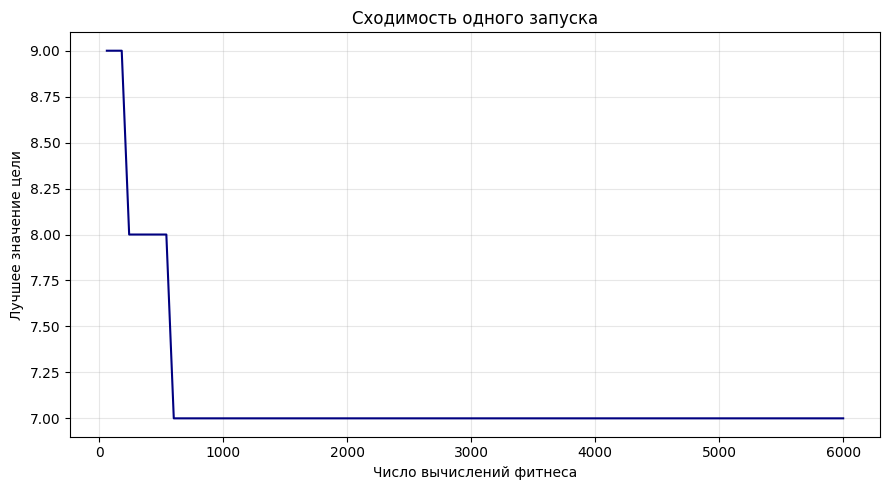

4674

In [3]:
config = GAConfig(seed=42)
result = GeneticAlgorithm(problem, config).run()
assert result['n_evals'] == config.budget
assert result['feasible']
best_x = np.asarray(result['best_x'], dtype=np.int8)

print(f"Мягкая цель: {result['best_objective']:.1f}")
print(f"Штраф предпочтений: {result['preference']}; дисбаланс: {result['imbalance']:.1f}")
print(f"Нагрузка: {result['loads']}")
print(f"Вычислений фитнеса: {result['n_evals']}; время: {result['elapsed_seconds']:.2f} с")
display(schedule_table(problem, best_x))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(result['eval_history'], result['best_history'], color='navy')
ax.set(xlabel='Число вычислений фитнеса', ylabel='Лучшее значение цели', title='Сходимость одного запуска')
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig('plots/single_run.png', dpi=150)
plt.show()
Path('results/single_run.json').write_text(json.dumps({'config': asdict(config), 'result': result}, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

Один запуск демонстрирует декодирование и работоспособность алгоритма, но не используется как доказательство эффективности. В `02_experiments.ipynb` выполняются независимые серии, сравнение обработки ограничений, двух мутаций и случайного допустимого поиска с тем же бюджетом.